# 📊 HR Employee Attrition Analysis

**Author:** [Nama Kamu]
**Tanggal:** [Tanggal]
**Dataset:** IBM HR Analytics Employee Attrition (Kaggle)

## 🎯 Business Problem
Perusahaan mengalami tingkat turnover karyawan yang tinggi. 
Tim HR ingin memahami:
1. **Faktor apa** yang paling berkorelasi dengan karyawan resign?
2. **Segmen karyawan mana** yang paling berisiko resign?
3. **Rekomendasi apa** yang bisa diambil HR untuk menekan attrition rate?

## 📋 Dataset Overview
- Sumber: IBM HR Analytics (Kaggle)
- Jumlah baris: ~1.470 karyawan
- Jumlah kolom: 35 fitur (demografi, kepuasan kerja, kompensasi, dll)
- Target: `Attrition` (Yes/No)

In [1]:
# ===== Standard Library =====
import pandas as pd
import numpy as np

# ===== Visualization =====
import matplotlib.pyplot as plt
import seaborn as sns

# ===== Settings =====
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 100

# Suppress warning (opsional)
import warnings
warnings.filterwarnings('ignore')

print("✅ Library berhasil diimport!")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")

✅ Library berhasil diimport!
Pandas version: 2.2.1
NumPy version: 1.26.4


In [8]:
# Load dataset
# df = pd.read_csv('C:\data2\py\portfolio-data-analysis\project-01-hr-attrition\data\raw\WA_Fn-UseC_-HR-Employee-Attrition.csv')
df = pd.read_csv(r'C:\data2\py\portfolio-data-analysis\project-01-hr-attrition\data\raw\WA_Fn-UseC_-HR-Employee-Attrition.csv')
#

print(f"Shape dataset: {df.shape}")
print(f"Jumlah baris: {df.shape[0]:,}")
print(f"Jumlah kolom: {df.shape[1]}")

# Tampilkan 5 baris pertama
df.head()

Shape dataset: (1470, 35)
Jumlah baris: 1,470
Jumlah kolom: 35


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [9]:
# Info dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [10]:
# Statistik deskriptif kolom numerik
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


In [11]:
# Cek kolom kategorikal
cat_cols = df.select_dtypes(include='object').columns.tolist()
num_cols = df.select_dtypes(include=np.number).columns.tolist()

print(f"🔤 Kolom kategorikal ({len(cat_cols)}):")
print(cat_cols)
print(f"\n🔢 Kolom numerik ({len(num_cols)}):")
print(num_cols)

🔤 Kolom kategorikal (9):
['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'Over18', 'OverTime']

🔢 Kolom numerik (26):
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [13]:
# Cek missing values
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': missing_pct
})
missing_df[missing_df['Missing Count'] > 0].sort_values('Missing Count', ascending=False)

,Missing Count,Missing %


In [14]:
# Cek duplikat
print(f"Jumlah duplikat: {df.duplicated().sum()}")

# Cek unique values kolom kategorikal yang menarik
for col in ['Attrition', 'Department', 'JobRole', 'Gender', 'OverTime', 'MaritalStatus']:
    print(f"\n📊 {col} ({df[col].nunique()} unique):")
    print(df[col].value_counts())

Jumlah duplikat: 0

📊 Attrition (2 unique):
Attrition
No     1233
Yes     237
Name: count, dtype: int64

📊 Department (3 unique):
Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64

📊 JobRole (9 unique):
JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52
Name: count, dtype: int64

📊 Gender (2 unique):
Gender
Male      882
Female    588
Name: count, dtype: int64

📊 OverTime (2 unique):
OverTime
No     1054
Yes     416
Name: count, dtype: int64

📊 MaritalStatus (3 unique):
MaritalStatus
Married     673
Single      470
Divorced    327
Name: count, dtype: int64


In [15]:
# 1. Cek kolom yang konstan (tidak informatif)
constant_cols = [col for col in df.columns if df[col].nunique() == 1]
print(f"Kolom konstan (drop): {constant_cols}")

# Drop kolom konstan
df_clean = df.drop(columns=constant_cols)
print(f"\nShape setelah drop kolom konstan: {df_clean.shape}")

Kolom konstan (drop): ['EmployeeCount', 'Over18', 'StandardHours']

Shape setelah drop kolom konstan: (1470, 32)


In [16]:
# 2. Cek kolom yang redundan (misal: EmployeeCount = 1 untuk semua)
# Di dataset ini biasanya 'EmployeeCount', 'Over18', 'StandardHours' konstan
print("Kolom yang tersisa:")
print(df_clean.columns.tolist())

Kolom yang tersisa:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [17]:
# 3. Konversi tipe data jika perlu
# Attrition biasanya object 'Yes'/'No' → ubah ke binary 1/0 untuk analisis
df_clean['Attrition_Binary'] = df_clean['Attrition'].map({'Yes': 1, 'No': 0})

# Cek hasil
print(df_clean[['Attrition', 'Attrition_Binary']].value_counts())
print(f"\nAttrition rate: {df_clean['Attrition_Binary'].mean() * 100:.2f}%")

Attrition  Attrition_Binary
No         0                   1233
Yes        1                    237
Name: count, dtype: int64

Attrition rate: 16.12%


In [22]:
# 4. Simpan data bersih ke folder processed
df_clean.to_csv(r'C:\data2\py\portfolio-data-analysis\project-01-hr-attrition\data\raw\WA_Fn-UseC_-HR-Employee-Attrition.csv', index=False)
print(" Data bersih tersimpan di data/processed/")

 Data bersih tersimpan di data/processed/


FileNotFoundError: [Errno 2] No such file or directory: '../reports/figures/01_attrition_distribution.png'

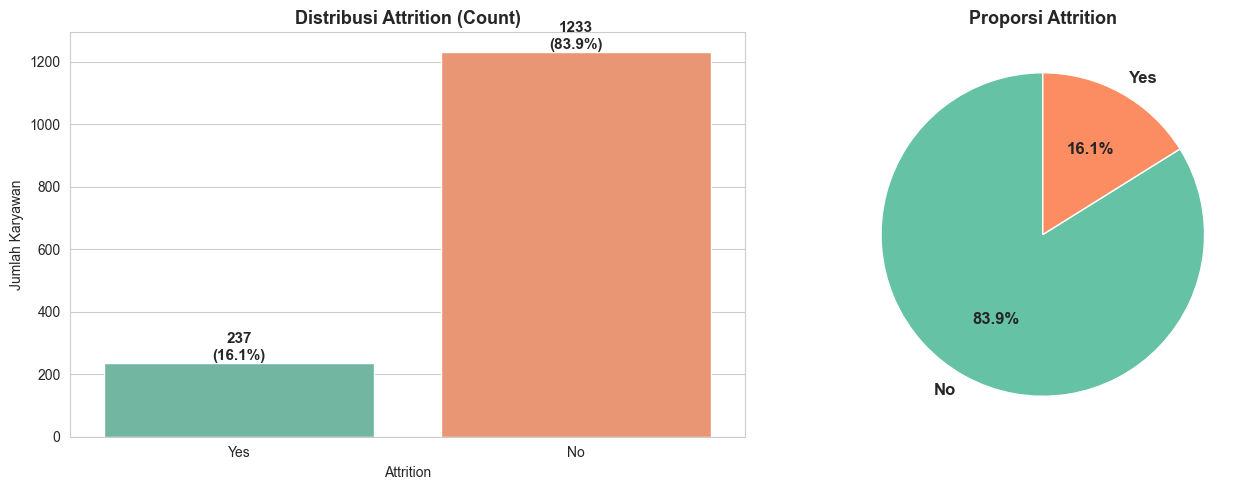

In [26]:
import os
# Visualisasi distribusi attrition
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Count plot
ax1 = sns.countplot(data=df_clean, x='Attrition', palette='Set2', ax=axes[0])
axes[0].set_title('Distribusi Attrition (Count)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Attrition')
axes[0].set_ylabel('Jumlah Karyawan')

# Tambahkan label persentase
total = len(df_clean)
for p in ax1.patches:
    count = int(p.get_height())
    pct = count / total * 100
    ax1.annotate(f'{count}\n({pct:.1f}%)',
                 (p.get_x() + p.get_width() / 2, p.get_height()),
                 ha='center', va='bottom', fontsize=11, fontweight='bold')

# Pie chart
attrition_counts = df_clean['Attrition'].value_counts()
axes[1].pie(attrition_counts, labels=attrition_counts.index,
            autopct='%1.1f%%', colors=sns.color_palette('Set2'),
            startangle=90, textprops={'fontsize': 12, 'fontweight': 'bold'})
axes[1].set_title('Proporsi Attrition', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('../reports/figures/01_attrition_distribution.png', dpi=100, bbox_inches='tight')
plt.show()

print(f"\n INSIGHT:")
print(f"Attrition rate: {df_clean['Attrition_Binary'].mean() * 100:.1f}%")
print(f"Artinya sekitar 1 dari {int(1/df_clean['Attrition_Binary'].mean())} karyawan resign.")
print(f"Dataset ini cukup imbalanced (minoritas positif) — penting untuk modeling nanti.")

               Department  total_karyawan  jumlah_resign  attrition_rate  \
2                   Sales             446             92        0.206278   
0         Human Resources              63             12        0.190476   
1  Research & Development             961            133        0.138398   

   attrition_rate_pct  
2               20.63  
0               19.05  
1               13.84  


FileNotFoundError: [Errno 2] No such file or directory: '../reports/figures/02_attrition_by_dept.png'

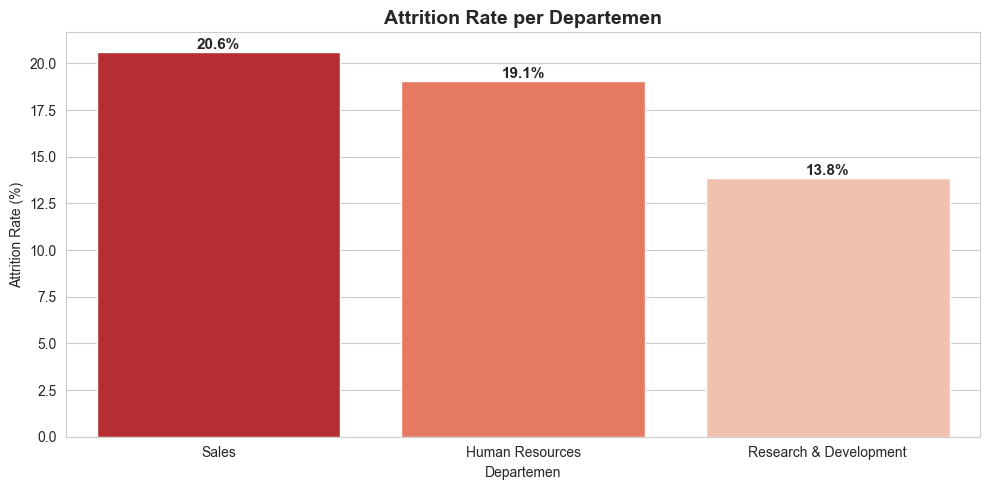

In [27]:
# Attrition per Departemen
# Attrition rate per departemen
dept_attrition = df_clean.groupby('Department').agg(
    total_karyawan=('Attrition_Binary', 'count'),
    jumlah_resign=('Attrition_Binary', 'sum'),
    attrition_rate=('Attrition_Binary', 'mean')
).reset_index()
dept_attrition['attrition_rate_pct'] = (dept_attrition['attrition_rate'] * 100).round(2)
dept_attrition = dept_attrition.sort_values('attrition_rate', ascending=False)

print(dept_attrition)

# Visualisasi
fig, ax = plt.subplots(figsize=(10, 5))
bars = sns.barplot(data=dept_attrition, x='Department', y='attrition_rate_pct',
                    palette='Reds_r', ax=ax)
ax.set_title('Attrition Rate per Departemen', fontsize=14, fontweight='bold')
ax.set_xlabel('Departemen')
ax.set_ylabel('Attrition Rate (%)')

# Label di bar
for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}%',
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('../reports/figures/02_attrition_by_dept.png', dpi=100, bbox_inches='tight')
plt.show()

print(f"\n💡 INSIGHT:")
top_dept = dept_attrition.iloc[0]
print(f"Departemen dengan attrition tertinggi: {top_dept['Department']} ({top_dept['attrition_rate_pct']}%)")

FileNotFoundError: [Errno 2] No such file or directory: '../reports/figures/03_numeric_features_vs_attrition.png'

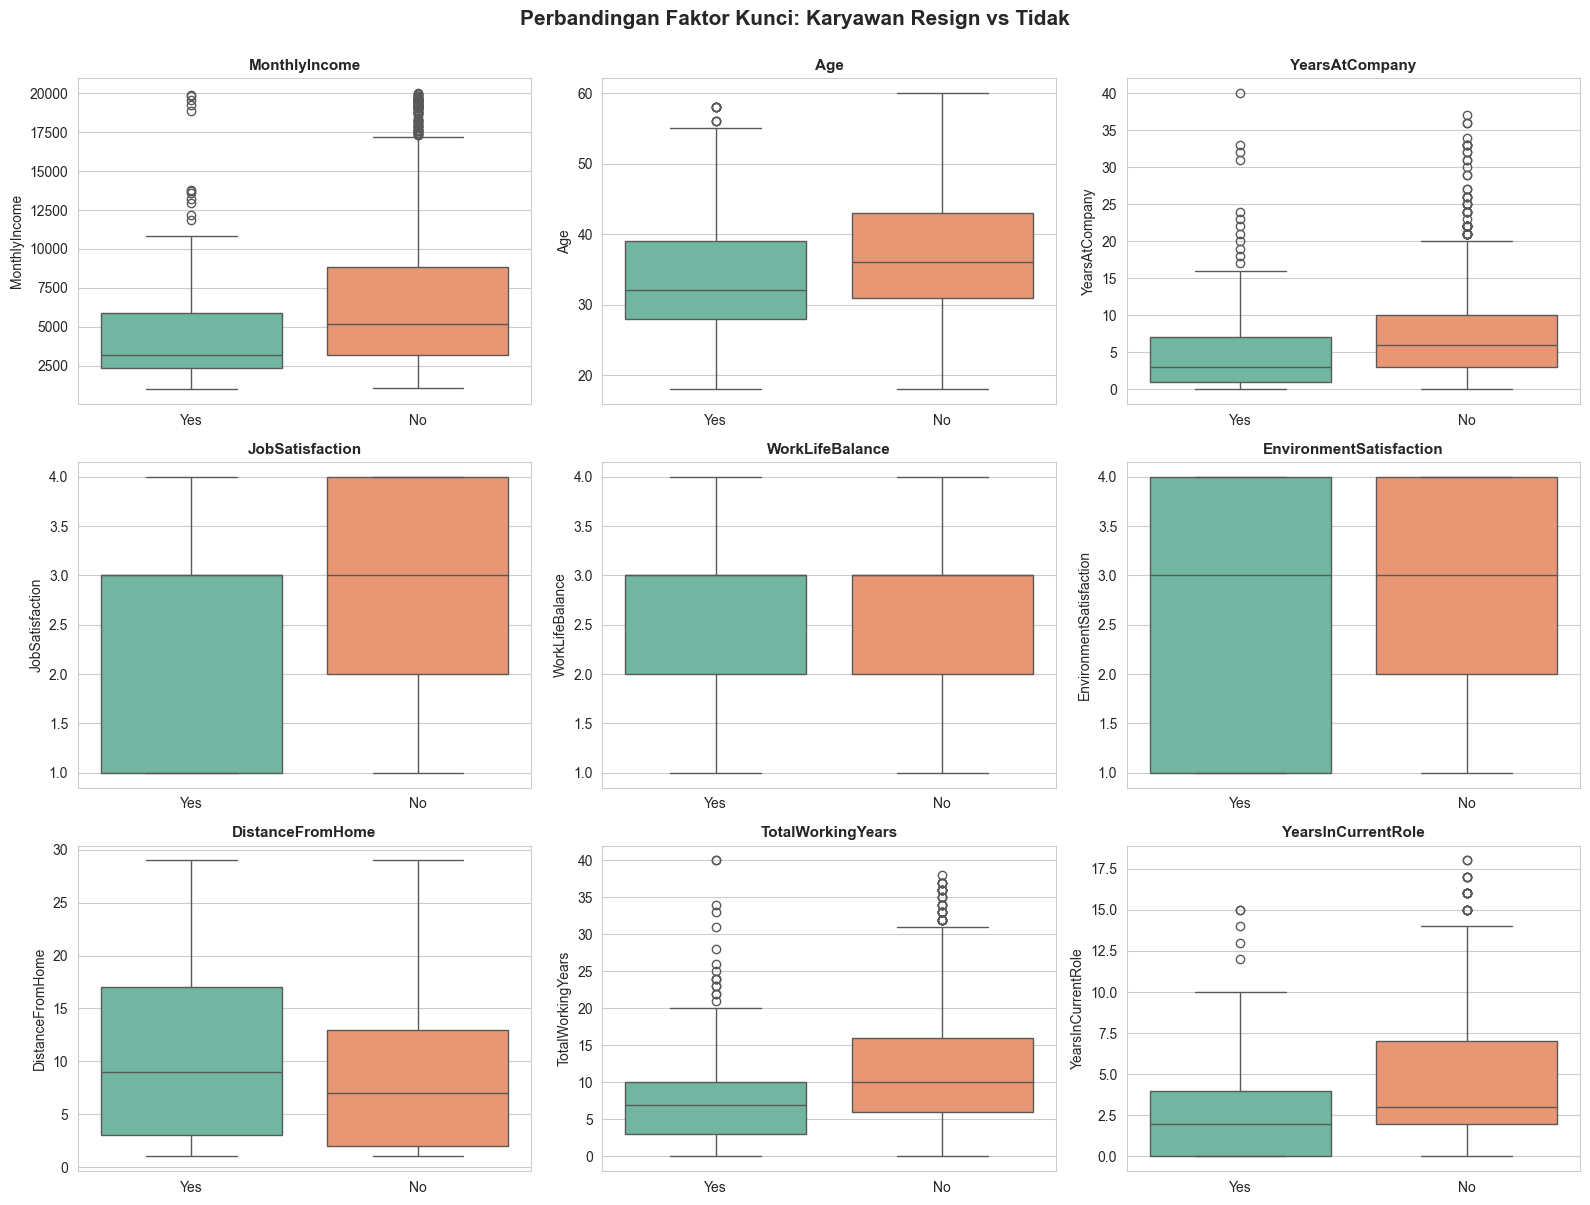

In [28]:
# Attrition vs Faktor Kompensasi & Work-Life

# Bandingkan fitur numerik kunci antara yang resign vs tidak
key_features = ['MonthlyIncome', 'Age', 'YearsAtCompany', 'JobSatisfaction',
                'WorkLifeBalance', 'EnvironmentSatisfaction', 'DistanceFromHome',
                'TotalWorkingYears', 'YearsInCurrentRole']

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for i, feat in enumerate(key_features):
    sns.boxplot(data=df_clean, x='Attrition', y=feat,
                palette='Set2', ax=axes[i])
    axes[i].set_title(f'{feat}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('')

plt.suptitle('Perbandingan Faktor Kunci: Karyawan Resign vs Tidak',
             fontsize=15, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig('../reports/figures/03_numeric_features_vs_attrition.png', dpi=100, bbox_inches='tight')
plt.show()

In [29]:
# Rata-rata fitur numerik per status attrition
numeric_summary = df_clean.groupby('Attrition')[key_features].mean().T.round(2)
numeric_summary['Selisih'] = (numeric_summary['Yes'] - numeric_summary['No']).round(2)
numeric_summary = numeric_summary.sort_values('Selisih')
print(numeric_summary)

print(f"\n💡 INSIGHT:")
print(f"Karyawan yang resign cenderung:")
print(f"- Pendapatan bulanan lebih rendah (~${numeric_summary.loc['MonthlyIncome', 'Selisih']:.0f} selisih)")
print(f"- Usia lebih muda (~{abs(numeric_summary.loc['Age', 'Selisih']):.0f} tahun lebih muda)")
print(f"- Masa kerja lebih singkat")

Attrition                     No      Yes  Selisih
MonthlyIncome            6832.74  4787.09 -2045.65
Age                        37.56    33.61    -3.95
TotalWorkingYears          11.86     8.24    -3.62
YearsAtCompany              7.37     5.13    -2.24
YearsInCurrentRole          4.48     2.90    -1.58
JobSatisfaction             2.78     2.47    -0.31
EnvironmentSatisfaction     2.77     2.46    -0.31
WorkLifeBalance             2.78     2.66    -0.12
DistanceFromHome            8.92    10.63     1.71

💡 INSIGHT:
Karyawan yang resign cenderung:
- Pendapatan bulanan lebih rendah (~$-2046 selisih)
- Usia lebih muda (~4 tahun lebih muda)
- Masa kerja lebih singkat


In [30]:
# EDA 4: Attrition vs OverTime & Job Role
# Attrition rate berdasarkan OverTime
overtime_attrition = df_clean.groupby('OverTime')['Attrition_Binary'].agg(['mean', 'count'])
overtime_attrition['mean_pct'] = (overtime_attrition['mean'] * 100).round(2)
print("Attrition rate berdasarkan OverTime:")
print(overtime_attrition)

Attrition rate berdasarkan OverTime:
              mean  count  mean_pct
OverTime                           
No        0.104364   1054     10.44
Yes       0.305288    416     30.53


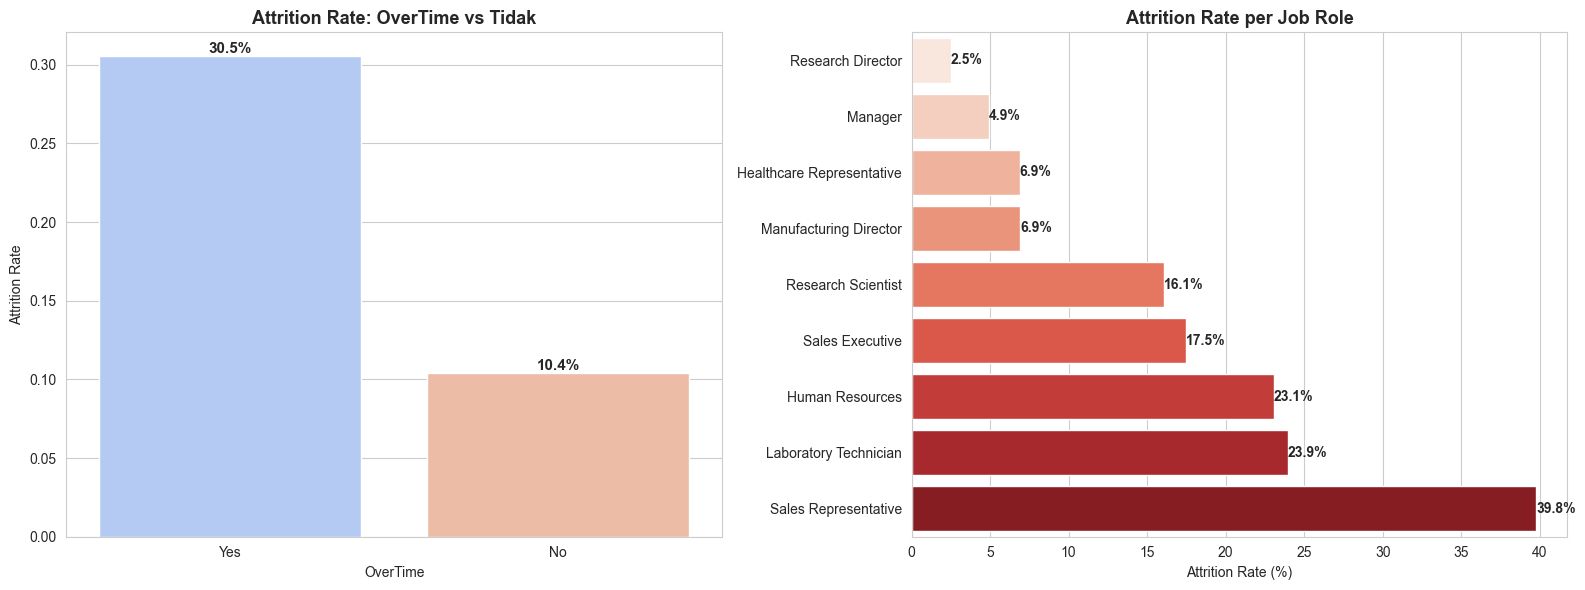


💡 INSIGHT:
Karyawan dengan OverTime: 30.5% attrition
Karyawan tanpa OverTime: 10.4% attrition
➡️ OverTime meningkatkan risiko resign ~2.9x lipat!

Job Role paling berisiko: Sales Representative (39.8%)


In [36]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Pastikan folder laporan/figures ada (Mencegah FileNotFoundError)
# os.makedirs('../reports/figures', exist_ok=True)

output_dir = os.path.abspath('../reports/figures')
os.makedirs(output_dir, exist_ok=True)

# Visualisasi 2 panel: OverTime & JobRole
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# OverTime
sns.barplot(data=df_clean, x='OverTime', y='Attrition_Binary',
            palette='coolwarm', ax=axes[0], estimator=np.mean, errorbar=None)
axes[0].set_title('Attrition Rate: OverTime vs Tidak', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Attrition Rate')
axes[0].set_xlabel('OverTime')

for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height()*100:.1f}%',
                     (p.get_x() + p.get_width()/2, p.get_height()),
                     ha='center', va='bottom', fontsize=11, fontweight='bold')

# JobRole
role_attrition = df_clean.groupby('JobRole')['Attrition_Binary'].mean().sort_values(ascending=True) * 100
sns.barplot(x=role_attrition.values, y=role_attrition.index,
            palette='Reds', ax=axes[1])
axes[1].set_title('Attrition Rate per Job Role', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Attrition Rate (%)')
axes[1].set_ylabel('')

for p in axes[1].patches:
    axes[1].annotate(f'{p.get_width():.1f}%',
                     (p.get_width(), p.get_y() + p.get_height()/2),
                     ha='left', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()

# 2. Simpan gambar setelah folder dipastikan aman
plt.savefig('../reports/figures/04_overtime_jobrole_attrition.png', dpi=100, bbox_inches='tight')
plt.savefig(os.path.join(output_dir, '04_overtime_jobrole_attrition.png'), dpi=100, bbox_inches='tight')
plt.show()

print(f"\n💡 INSIGHT:")
ot_yes = df_clean[df_clean['OverTime']=='Yes']['Attrition_Binary'].mean()*100
ot_no  = df_clean[df_clean['OverTime']=='No']['Attrition_Binary'].mean()*100
print(f"Karyawan dengan OverTime: {ot_yes:.1f}% attrition")
print(f"Karyawan tanpa OverTime: {ot_no:.1f}% attrition")
print(f"➡️ OverTime meningkatkan risiko resign ~{ot_yes/ot_no:.1f}x lipat!")
print(f"\nJob Role paling berisiko: {role_attrition.idxmax()} ({role_attrition.max():.1f}%)")

In [32]:
# EDA 5: Correlation Heatmap
# Korelasi fitur numerik dengan Attrition
num_features_corr = df_clean.select_dtypes(include=np.number).columns.tolist()
corr_matrix = df_clean[num_features_corr].corr()

# Korelasi terhadap Attrition, urutkan
attrition_corr = corr_matrix['Attrition_Binary'].drop('Attrition_Binary').sort_values()

print("Top 10 fitur paling NEGATIF berkorelasi dengan Attrition:")
print(attrition_corr.head(10))
print("\nTop 10 fitur paling POSITIF berkorelasi dengan Attrition:")
print(attrition_corr.tail(10))

Top 10 fitur paling NEGATIF berkorelasi dengan Attrition:
TotalWorkingYears      -0.171063
JobLevel               -0.169105
YearsInCurrentRole     -0.160545
MonthlyIncome          -0.159840
Age                    -0.159205
YearsWithCurrManager   -0.156199
StockOptionLevel       -0.137145
YearsAtCompany         -0.134392
JobInvolvement         -0.130016
JobSatisfaction        -0.103481
Name: Attrition_Binary, dtype: float64

Top 10 fitur paling POSITIF berkorelasi dengan Attrition:
RelationshipSatisfaction   -0.045872
YearsSinceLastPromotion    -0.033019
Education                  -0.031373
PercentSalaryHike          -0.013478
EmployeeNumber             -0.010577
HourlyRate                 -0.006846
PerformanceRating           0.002889
MonthlyRate                 0.015170
NumCompaniesWorked          0.043494
DistanceFromHome            0.077924
Name: Attrition_Binary, dtype: float64


In [33]:
#  Kesimpulan & Rekomendasi
print("=" * 70)
print(" RINGKASAN INSIGHT & REKOMENDASI")
print("=" * 70)
print(f"""
📊 DATA OVERVIEW
- Total karyawan: {len(df_clean):,}
- Attrition rate: {df_clean['Attrition_Binary'].mean()*100:.1f}%
- Dataset imbalanced → perlu handling (SMOTE/class weight) saat modeling

🔍 FAKTOR UTAMA PENYEBAB ATTRITION
1. OverTime: Karyawan lembur punya risiko resign {ot_yes/ot_no:.1f}x lebih tinggi
2. MonthlyIncome: Karyawan resign berpenghasilan lebih rendah
3. Job Role: {role_attrition.idxmax()} & {role_attrition.nlargest(2).index[1]} paling berisiko
4. Age & Tenure: Karyawan muda & masa kerja singkat lebih sering resign

💡 REKOMENDASI UNTUK HR
1. Review kebijakan lembur (OverTime) — mungkin workload tidak seimbang
2. Evaluasi kompensasi untuk level entry & job role tertentu
3. Program retensi untuk karyawan baru (< 3 tahun)
4. Fokuskan program engagement untuk role: {role_attrition.idxmax()}

🎯 NEXT STEP (PROJECT LANJUTAN)
- Bangun model klasifikasi (Logistic Regression / Random Forest)
- Handling class imbalance (SMOTE)
- Feature importance untuk validasi insight EDA
- Dashboard interaktif dengan Streamlit
""")
print("=" * 70)

 RINGKASAN INSIGHT & REKOMENDASI


NameError: name 'ot_yes' is not defined

##  Next Steps

Notebook ini adalah tahap **EDA (Exploratory Data Analysis)**. 
Untuk project selanjutnya, akan dibuat:

- [ ] `02_hr_attrition_modeling.ipynb` — Model prediksi attrition
- [ ] `app/streamlit_app.py` — Dashboard interaktif
- [ ] Update `README.md` di root project
- [ ] Publish ke GitHub & LinkedIn

##  Referensi
- Dataset: [IBM HR Analytics Attrition](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset)